# 08 · Two diffusively coupled FitzHugh–Nagumo neurons
## Goal
Establish a checked pair experiment before graph ensembles. Study identical and mismatched oscillators, coupling strength, initial phase, and complete versus phase synchronization. This is a deterministic mathematical experiment, not a calibrated electrical or chemical synapse.

**Scope:** FHN only; dimensionless shared time; symmetric nonnegative diffusive activation coupling; no delays, noise, resets or synaptic variables. Future spatial and excitatory/inhibitory experiments are specified below, not silently included here. All figures and tables are saved in `results/fhn_pair/`. NumPy, SciPy, pandas, Matplotlib and Jupyter are required; no download or installation occurs.

## Observed results
The 28 experiments cover two current pairs, two initial phase offsets and seven coupling strengths. At phase offset 0.2 and g=0.1, identical neurons have RMS state disagreement below 2×10⁻¹⁶; mismatched neurons have RMS disagreement 0.138513 and phase lag −0.014991 cycles despite a phase-locking value near 1. These are finite-window observations, not an exact synchronization boundary.

The isolated period is 39.474414979 model-time units. All 10 structural/numerical checks pass. Independent DOP853/Radau trajectories agree within 7.88×10⁻⁸ in state and 5.29×10⁻⁸ in spike time for the strongly contracting benchmark. In the later 2400–3200 window, the mismatched g=0.1 lag and period-based frequency remain unchanged to the displayed precision, while sampled RMS changes from 0.138513 to 0.138572. Count frequencies can differ by one event across shifted windows even for settled periodic motion.


## Setup: equations and graph convention
Retain notebook 04's parameters $a=0.7,b=0.8,\epsilon=0.08$:
$$\dot v_i=v_i-v_i^3/3-w_i+I_i+g\sum_j W_{ij}(v_j-v_i),\quad
\dot w_i=\epsilon(v_i+a-bw_i).$$
$W_{ij}$ is the weight **from source j to recipient i**. The pair has $W_{12}=W_{21}=1$, diagonal zero. $g$ is per-edge strength, without degree normalization. The numerical function accepts a weighted graph but only the pair is studied here; it is not yet a mixed-model solver.

Use $I_1=I_2=0.5$ for identical oscillators and $(0.5,0.55)$ for mismatch. These are explicitly chosen exploratory parameter cuts. Initial states are sampled at fractions 0.2 and 0.5 of a settled isolated cycle, plus a synchronous initial condition. Each run lasts 1600 time units; discard the first 800. These are finite windows, not a complete attractor survey.

For a symmetric graph $L=D-W$, coupling is $-gLv$. For the pair the difference variables obey
$$\dot{\delta v}=(1-\tfrac13(v_1^2+v_1v_2+v_2^2)-2g)\delta v-\delta w,\quad
\dot{\delta w}=\epsilon(\delta v-b\delta w)$$
when inputs are identical. With $E=(\delta v^2+\delta w^2/\epsilon)/2$,
$$\dot E\le (1-2g)\delta v^2-b\delta w^2.$$
Thus $g>1/2$ is a **sufficient global contraction bound** for identical neurons, not the exact synchronization threshold. The identical-state manifold is invariant for any g; that alone does not establish its stability. Mismatched inputs add $(I_1-I_2)\delta v$ and break exact invariance.

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}
Isolated period: 39.47441497889804


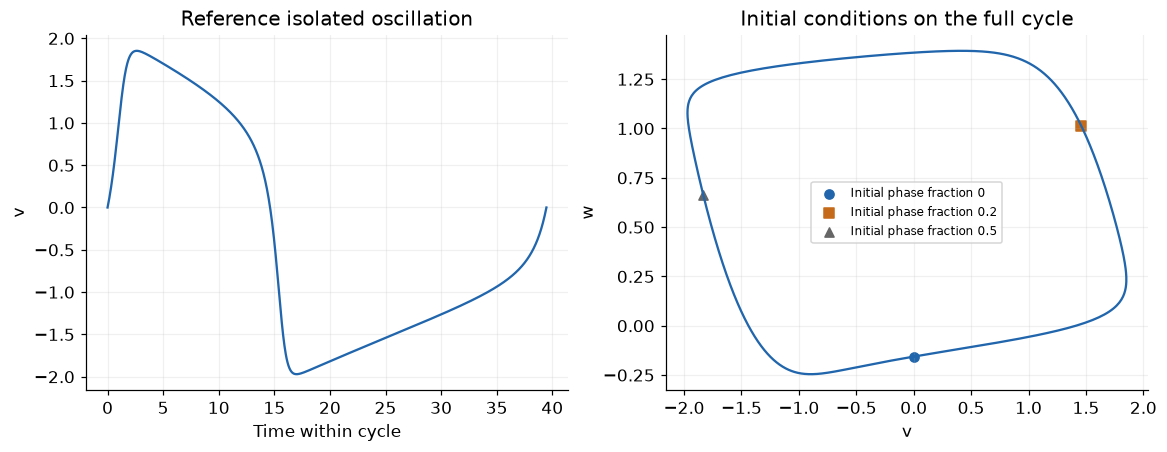

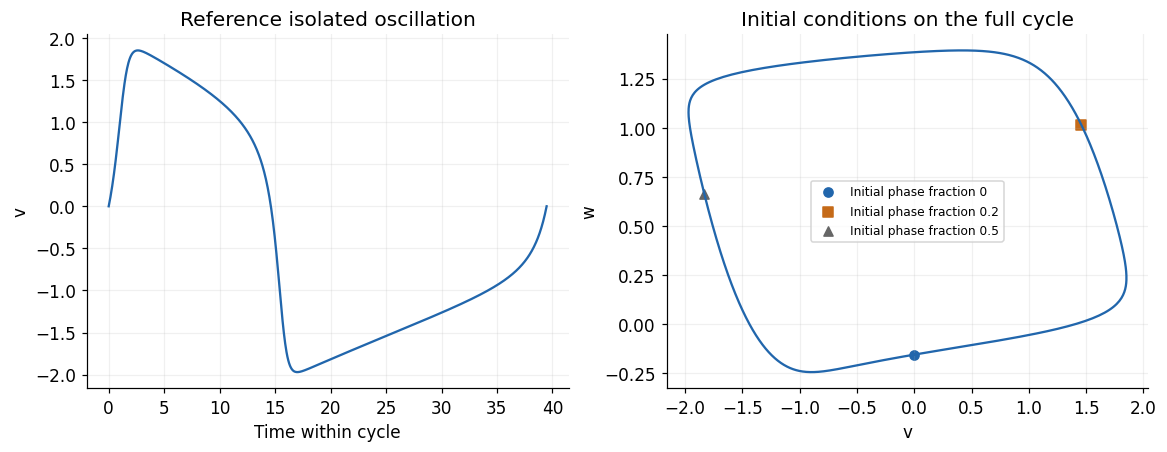

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy, matplotlib
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from IPython.display import display
OUT=Path('results/fhn_pair'); OUT.mkdir(parents=True,exist_ok=True)
a,b,eps=0.7,0.8,0.08
W=np.array([[0.,1.],[1.,0.]])
BLUE,ORANGE='#2166AC','#C56A18'
plt.rcParams.update({'font.size':11,'figure.dpi':110,'savefig.dpi':160,
 'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,matplotlib=matplotlib.__version__)
print(versions)
def save(fig,name):
 fig.savefig(OUT/(name+'.png'),bbox_inches='tight'); plt.show(); plt.close(fig)
def coupling(v,weights,g):
 return g*(weights@v-weights.sum(axis=1)*v)
def integrate(initial, currents, g=0., weights=W, end=1600., method='DOP853',rtol=1e-9,atol=1e-11):
 initial=np.asarray(initial,float); currents=np.asarray(currents,float); weights=np.asarray(weights,float)
 N=len(currents)
 if initial.shape!=(N,2) or weights.shape!=(N,N): raise ValueError('State or graph shape mismatch')
 if not np.isfinite(weights).all() or np.any(weights<0) or np.any(np.diag(weights)!=0) or g<0: raise ValueError('Use finite nonnegative weights, zero diagonal and g>=0')
 def rhs(t,y):
  z=y.reshape(N,2); v,w=z.T
  return np.column_stack((v-v**3/3-w+currents+coupling(v,weights,g),eps*(v+a-b*w))).ravel()
 events=[]
 for i in range(N):
  def event(t,y,index=i): return y[2*index]
  event.direction=1; event.terminal=False; events.append(event)
 sol=solve_ivp(rhs,(0,end),initial.ravel(),dense_output=True,events=events,
  method=method,rtol=rtol,atol=atol,max_step=.5)
 if not sol.success: raise RuntimeError(sol.message)
 return sol
# Obtain a settled cycle from the same isolated FHN equation, not a phase approximation.
iso=integrate([[2.,-.5]],[.5],weights=np.zeros((1,1)),end=1000.)
t0,t1=iso.t_events[0][-2:]; T=t1-t0
cycle0=iso.sol(t0); cycle=lambda fraction: iso.sol(t0+fraction*T)
print('Isolated period:',T)
fig,ax=plt.subplots(1,2,figsize=(10.5,4),layout='constrained')
tt=np.linspace(t0,t1,1001); zz=iso.sol(tt)
ax[0].plot(tt-t0,zz[0],color=BLUE); ax[0].set(xlabel='Time within cycle',ylabel='v',title='Reference isolated oscillation')
ax[1].plot(zz[0],zz[1],color=BLUE)
for q,col,mark in [(0,BLUE,'o'),(.2,ORANGE,'s'),(.5,'.4','^')]:
 z=cycle(q); ax[1].scatter(*z,color=col,marker=mark,label=f'Initial phase fraction {q:g}')
ax[1].set(xlabel='v',ylabel='w',title='Initial conditions on the full cycle'); ax[1].legend(fontsize=8)
save(fig,'01_reference_cycle')

## 1. Define measurements before scanning
A spike is a positive crossing of $v=0$ with no reset. Frequencies are event counts divided by the 800-unit observation window; they have finite-window resolution $1/800$. Period-based frequencies are also reported.

State disagreement is the sampled RMS of $\sqrt{(v_1-v_2)^2+(w_1-w_2)^2}$; coordinates have the stated mathematical scaling. Event phase is linearly interpolated **only between consecutive observed crossings**. The pair phase-locking value is $|\langle e^{i(\phi_1-\phi_2)}\rangle|$; high values may describe nonzero-lag locking, not identical states. Lag is reported in cycles, wrapped to $[-1/2,1/2]$. Phase slips count the integer-bin range of the unwrapped phase difference and remain sensitive to window boundaries. Rest/suppressed spiking makes event phase undefined. Sampling is every 0.2 time units; solver events are not obtained from this grid.

,case,initial_phase_fraction,g,rms_state_difference,count_frequency_1,period_frequency_1,count_frequency_2,period_frequency_2,phase_locking_value,lag_cycles,phase_slip_bin_range
0,identical,0.2,0.00,1.855481e+00,0.02500,0.025333,0.02500,0.025333,1.000000,-2.000000e-01,0
2,identical,0.2,0.02,1.412702e-04,0.02500,0.025333,0.02500,0.025333,1.000000,-5.724844e-06,0
4,identical,0.2,0.10,1.323236e-16,0.02500,0.025333,0.02500,0.025333,1.000000,-5.768334e-17,0
6,identical,0.2,0.60,0.000000e+00,0.02500,0.025333,0.02500,0.025333,1.000000,-5.502441e-17,0
14,mismatched,0.2,0.00,1.528708e+00,0.02500,0.025333,0.02625,0.025923,0.690499,1.011168e-01,0
16,mismatched,0.2,0.02,6.000354e-01,0.02625,0.025738,0.02625,0.025738,1.000000,-5.408742e-02,0
18,mismatched,0.2,0.10,1.385130e-01,0.02625,0.025667,0.02625,0.025667,1.000000,-1.499087e-02,0
20,mismatched,0.2,0.60,3.201255e-02,0.02625,0.025650,0.02625,0.025650,1.000000,-2.010776e-03,0


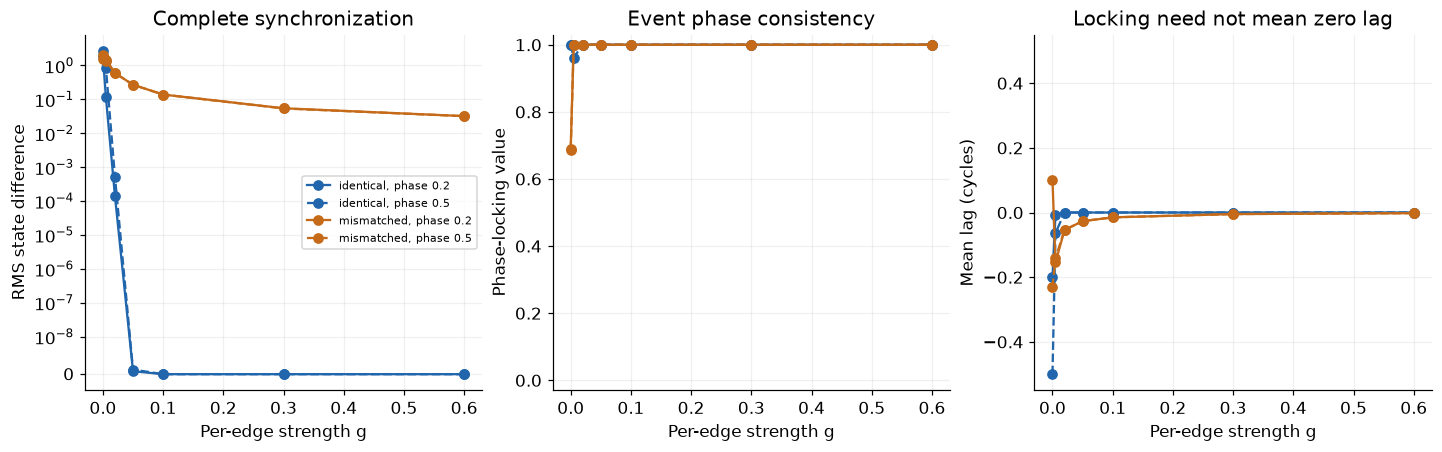

In [3]:
BURN,END=800.,1600.
grid=np.arange(BURN,END+.01,.2)
def metrics(sol):
 z=sol.sol(grid).reshape(2,2,-1); delta=z[0]-z[1]
 row={'rms_state_difference':float(np.sqrt(np.mean(np.sum(delta**2,axis=0))))}
 phase=[]
 for i,events in enumerate(sol.t_events):
  e=events[(events>=BURN)&(events<=END)]
  row[f'count_frequency_{i+1}']=len(e)/(END-BURN)
  row[f'period_frequency_{i+1}']=1/np.diff(e).mean() if len(e)>1 else np.nan
  p=np.full(grid.shape,np.nan)
  if len(events)>=2:
   inside=(grid>=events[0])&(grid<=events[-1])
   p[inside]=np.interp(grid[inside],events,2*np.pi*np.arange(len(events)))
  phase.append(p)
 d=phase[0]-phase[1]; valid=np.isfinite(d)
 if valid.sum()>10:
  d=d[valid]; order=np.mean(np.exp(1j*d))
  row.update(phase_locking_value=float(abs(order)),lag_cycles=float(np.angle(order)/(2*np.pi)),
   phase_slip_bin_range=int(np.ptp(np.floor((d-d[0])/(2*np.pi)+.5))))
 else: row.update(phase_locking_value=np.nan,lag_cycles=np.nan,phase_slip_bin_range=np.nan)
 return row
strengths=[0.,.005,.02,.05,.1,.3,.6]
runs={}; rows=[]
for label,inputs,offsets in [('identical',[.5,.5],[.2,.5]),('mismatched',[.5,.55],[.2,.5])]:
 for offset in offsets:
  for g in strengths:
   sol=integrate([cycle0,cycle(offset)],inputs,g)
   runs[(label,offset,g)]=sol
   rows.append(dict(case=label,initial_phase_fraction=offset,g=g,**metrics(sol)))
scan=pd.DataFrame(rows); scan.to_csv(OUT/'coupling_scan.csv',index=False)
display(scan[(scan.initial_phase_fraction==.2)&scan.g.isin([0,.02,.1,.6])])
fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for label,col in [('identical',BLUE),('mismatched',ORANGE)]:
 for offset,style in [(.2,'-'),(.5,'--')]:
  p=scan[(scan.case==label)&(scan.initial_phase_fraction==offset)]
  for ax,key in zip(axs,['rms_state_difference','phase_locking_value','lag_cycles']):
   ax.plot(p.g,p[key],'o'+style,color=col,label=f'{label}, phase {offset}')
axs[0].set_yscale('symlog',linthresh=1e-8)
axs[0].set(ylabel='RMS state difference',title='Complete synchronization')
axs[1].set(ylabel='Phase-locking value',ylim=(-.03,1.03),title='Event phase consistency')
axs[2].set(ylabel='Mean lag (cycles)',ylim=(-.55,.55),title='Locking need not mean zero lag')
for ax in axs: ax.set_xlabel('Per-edge strength g')
axs[0].legend(fontsize=7.5)
save(fig,'02_coupling_scan')

## 2. Inspect trajectories alongside scalar metrics
The following panels show the last 160 time units of selected runs. A fixed offset can yield a high phase-locking value at zero coupling for identical oscillators; it is not evidence that coupling has stabilized synchrony. Use state difference, lag, and different initial conditions together.

Energy curves are displayed with a floor of 10⁻²⁸; this is a plotting floor, not a measured residual. The analytical bound is evaluated for identical inputs only.

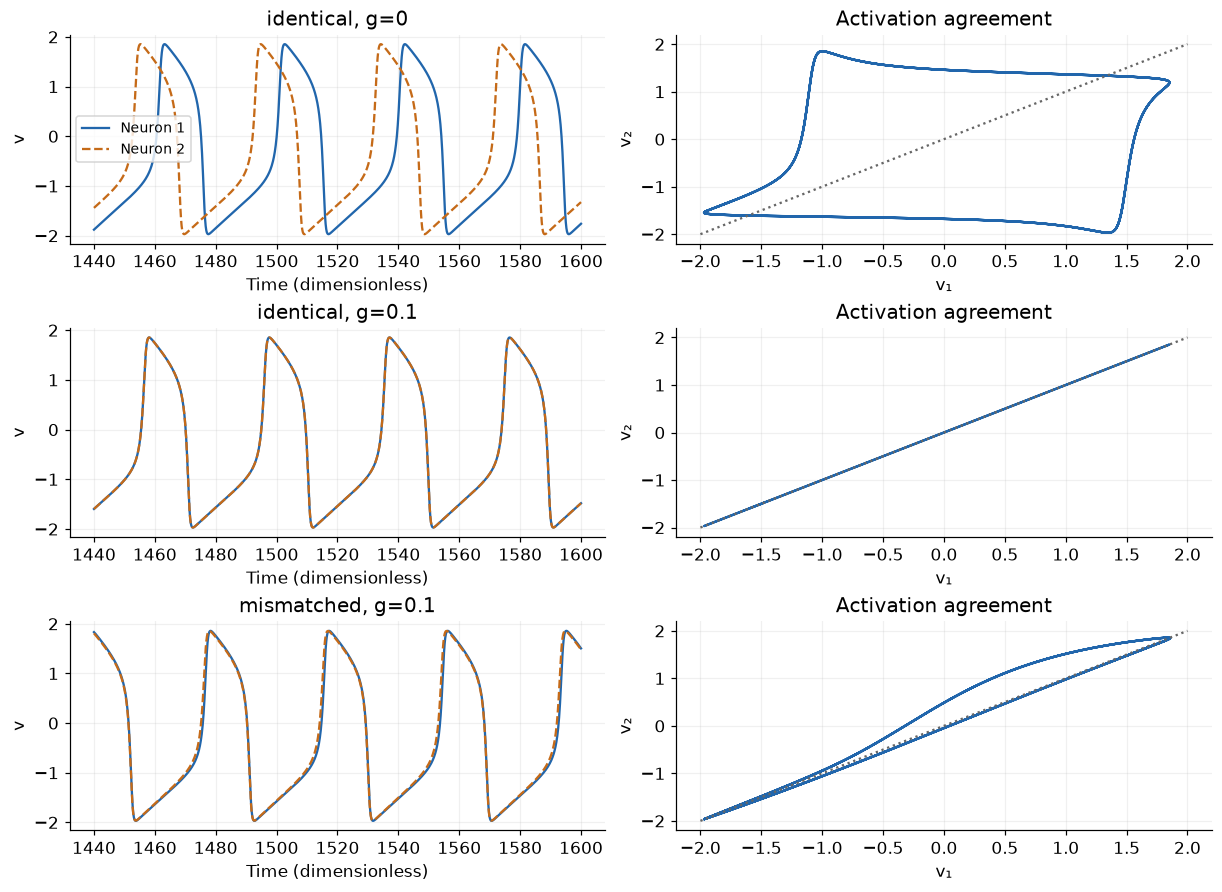

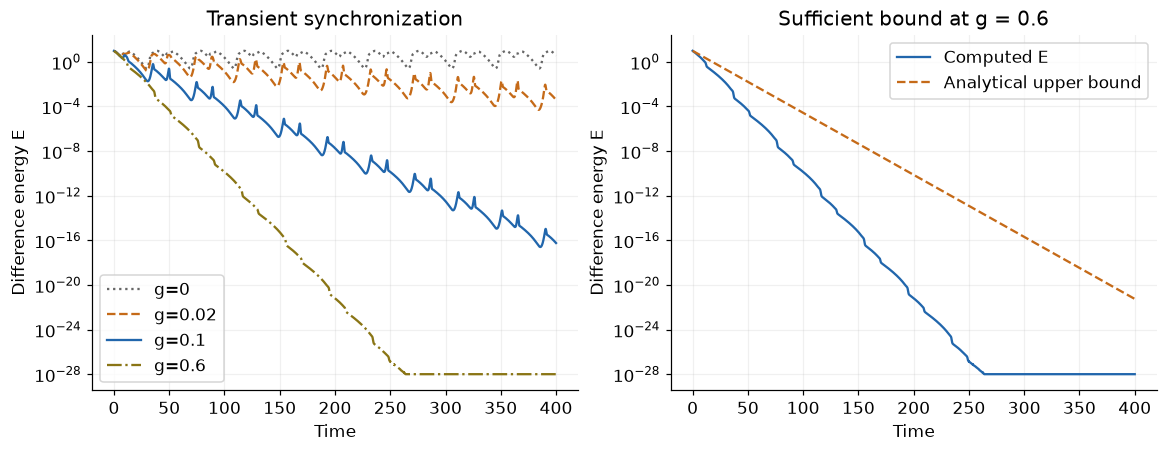

In [5]:
fig,axs=plt.subplots(3,2,figsize=(11,8),layout='constrained')
tail=np.linspace(END-160,END,1601)
for r,(label,g) in enumerate([('identical',0.),('identical',.1),('mismatched',.1)]):
 sol=runs[(label,.2,g)]; z=sol.sol(tail).reshape(2,2,-1)
 axs[r,0].plot(tail,z[0,0],color=BLUE,label='Neuron 1')
 axs[r,0].plot(tail,z[1,0],'--',color=ORANGE,label='Neuron 2')
 axs[r,0].set(ylabel='v',title=f'{label}, g={g:g}')
 axs[r,1].plot(z[0,0],z[1,0],color=BLUE)
 axs[r,1].plot([-2,2],[-2,2],':',color='.4')
 axs[r,1].set(xlabel='v₁',ylabel='v₂',title='Activation agreement')
axs[0,0].legend(fontsize=9)
for ax in axs[:,0]: ax.set_xlabel('Time (dimensionless)')
save(fig,'03_selected_trajectories')
fig,axs=plt.subplots(1,2,figsize=(10.5,4),layout='constrained')
times=np.linspace(0,400,4001)
for g,col,style in [(0.,'.4',':'),(.02,ORANGE,'--'),(.1,BLUE,'-'),(.6,'#8A7515','-.')]:
 z=runs[('identical',.2,g)].sol(times).reshape(2,2,-1)
 dv=z[0,0]-z[1,0]; dw=z[0,1]-z[1,1]; energy=(dv**2+dw**2/eps)/2
 axs[0].semilogy(times,np.maximum(energy,1e-28),color=col,linestyle=style,label=f'g={g:g}')
 if g==.6:
  bound=energy[0]*np.exp(-2*min(2*g-1,b*eps)*times)
  axs[1].semilogy(times,np.maximum(energy,1e-28),label='Computed E',color=BLUE)
  axs[1].semilogy(times,bound,'--',label='Analytical upper bound',color=ORANGE)
axs[0].set(xlabel='Time',ylabel='Difference energy E',title='Transient synchronization'); axs[0].legend()
axs[1].set(xlabel='Time',ylabel='Difference energy E',title='Sufficient bound at g = 0.6'); axs[1].legend()
save(fig,'04_difference_energy')

## 3. Numerical and structural checks
Check the graph sign, conservation of summed diffusive input for symmetric weights, zero-coupling agreement with separately integrated neurons, the invariant identical-state manifold, the sufficient energy bound, and solver convergence. Pointwise convergence is tested in the strongly contracting identical case; it is not extrapolated to every near-locking boundary. Recompute finite-window metrics after doubling the burn-in and observation horizon for representative runs.

,case,g,window,rms_state_difference,count_frequency_1,period_frequency_1,count_frequency_2,period_frequency_2,phase_locking_value,lag_cycles,phase_slip_bin_range
0,identical,0.1,800–1600,1.323236e-16,0.02500,0.025333,0.02500,0.025333,1.0,-5.768334e-17,0
1,identical,0.1,2400–3200,0.000000e+00,0.02625,0.025333,0.02625,0.025333,1.0,-1.100982e-17,0
2,mismatched,0.1,800–1600,1.385130e-01,0.02625,0.025667,0.02625,0.025667,1.0,-1.499087e-02,0
3,mismatched,0.1,2400–3200,1.385723e-01,0.02625,0.025667,0.02625,0.025667,1.0,-1.499087e-02,0


,check,error,limit,passed
0,Coupling agrees with pair formula,1.110223e-16,1.000000e-12,True
1,Symmetric coupling sum zero,0.000000e+00,1.000000e-12,True
2,Identical voltages give zero coupling,0.000000e+00,1.000000e-12,True
3,Zero coupling equals independent neuron 1,9.429579e-09,2.000000e-06,True
4,Zero coupling equals independent neuron 2,9.281867e-09,2.000000e-06,True
5,Identical-state manifold,0.000000e+00,1.000000e-12,True
6,Global contraction upper bound excess,0.000000e+00,1.000000e-08,True
7,DOP853 versus Radau state difference,7.876049e-08,1.000000e-05,True
8,Spike time convergence neuron 1,5.283005e-08,1.000000e-05,True
9,Spike time convergence neuron 2,5.283005e-08,1.000000e-05,True


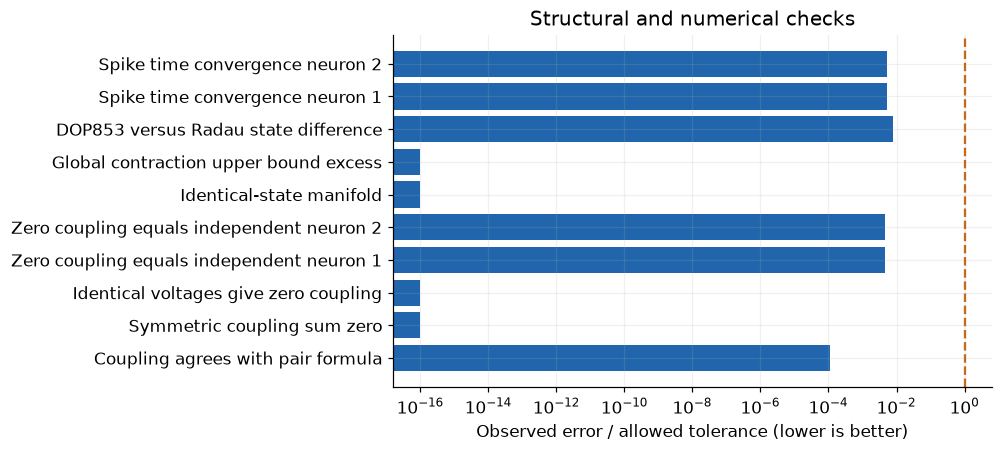

Saved 28 pair experiments and 10 passed checks.


In [7]:
checks=[]
def check(name,error,limit):
 checks.append(dict(check=name,error=float(error),limit=limit,passed=bool(error<limit)))
vtest=np.array([2.,-1.]); c=coupling(vtest,W,.3)
check('Coupling agrees with pair formula',np.max(abs(c-[-.9,.9])),1e-12)
check('Symmetric coupling sum zero',abs(c.sum()),1e-12)
check('Identical voltages give zero coupling',np.max(abs(coupling(np.ones(2),W,.3))),1e-12)
free=runs[('identical',.2,0.)]; tcheck=np.linspace(0,200,2001)
for i,initial in enumerate([cycle0,cycle(.2)]):
 solo=integrate([initial],[.5],weights=np.zeros((1,1)),end=200.)
 check(f'Zero coupling equals independent neuron {i+1}',np.max(abs(free.sol(tcheck)[2*i:2*i+2]-solo.sol(tcheck))),2e-6)
same=integrate([cycle0,cycle0],[.5,.5],.1,end=200.)
check('Identical-state manifold',np.max(abs(same.sol(tcheck)[:2]-same.sol(tcheck)[2:])),1e-12)
strong=runs[('identical',.2,.6)]
z=strong.sol(times).reshape(2,2,-1); d=z[0]-z[1]; energy=(d[0]**2+d[1]**2/eps)/2
bound=energy[0]*np.exp(-2*min(.2,b*eps)*times)
check('Global contraction upper bound excess',np.max(energy-bound),1e-8)
reference=integrate([cycle0,cycle(.2)],[.5,.5],.6,method='Radau',rtol=2e-10,atol=2e-12)
check('DOP853 versus Radau state difference',np.max(abs(strong.sol(grid)-reference.sol(grid))),1e-5)
for i in range(2):
 e=strong.t_events[i]; er=reference.t_events[i]
 assert len(e)==len(er)
 check(f'Spike time convergence neuron {i+1}',np.max(abs(e-er)),1e-5)
window_rows=[]
for label,g in [('identical',.1),('mismatched',.1)]:
 inputs=[.5,.5] if label=='identical' else [.5,.55]
 long=integrate([cycle0,cycle(.2)],inputs,g,end=3200.)
 # Translate the second 1600-unit interval to the original measurement convention.
 class Shifted:
  t_events=[e-1600 for e in long.t_events]
  def sol(self,t): return long.sol(np.asarray(t)+1600)
 window_rows.append(dict(case=label,g=g,window='800–1600',**metrics(runs[(label,.2,g)])))
 window_rows.append(dict(case=label,g=g,window='2400–3200',**metrics(Shifted())))
windows=pd.DataFrame(window_rows); windows.to_csv(OUT/'window_sensitivity.csv',index=False)
display(windows)
validation=pd.DataFrame(checks); display(validation); validation.to_csv(OUT/'validation_checks.csv',index=False)
assert validation.passed.all()
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
ax.barh(np.arange(len(checks)),np.maximum(validation.error/validation.limit,1e-16),color=BLUE)
ax.set_yticks(np.arange(len(checks)),validation['check']); ax.axvline(1,color=ORANGE,linestyle='--')
ax.set(xscale='log',xlabel='Observed error / allowed tolerance (lower is better)',title='Structural and numerical checks')
save(fig,'05_validation')
event_rows=[]
for (label,offset,g),sol in runs.items():
 for i,events in enumerate(sol.t_events):
  event_rows.extend(dict(case=label,initial_phase_fraction=offset,g=g,node=i,time=float(t)) for t in events)
pd.DataFrame(event_rows).to_csv(OUT/'spike_events.csv',index=False)
summary=dict(versions=versions,units='dimensionless',a=a,b=b,epsilon=eps,isolated_period=float(T),
 strengths=strengths,initial_phase_fractions=[.2,.5],duration=END,burn_in=BURN,
 checks_passed=int(validation.passed.sum()),experiment_count=len(scan),sufficient_identical_contraction_g_gt=.5)
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
print('Saved',len(scan),'pair experiments and',len(checks),'passed checks.')

## Next steps: spatial coupling, then excitation/inhibition
This pair study separates three choices that we will preserve in subsequent notebooks:

| Layer | Future specification |
|---|---|
| Node dynamics | FHN first; later model identifier, parameters, state, observation and input channel per node |
| Connections and geometry | Graph adjacency and optional node positions; no self-connections |
| Interaction | Diffusive activation now; chemical/current-based synapses later |

**Next notebook:** a homogeneous FHN square lattice with four nearest neighbors, comparing open and periodic boundaries with explicit lattice spacing. No boundary choice or lattice size is fixed in this pair notebook.

For distance coupling a candidate is
$$W_{ij}=\mathbf1_{i\ne j}\,\mathbf1_{d_{ij}\le R}(\ell/d_{ij})^p,$$
with $p=2$ as one experiment, nearest-neighbor spacing $\ell$, and optional cutoff R. Open-grid Euclidean distance and periodic minimum-image distance are different models. Setting R=ℓ on a square grid recovers the four-neighbor graph; full distance coupling uses all off-diagonal pairs. Zero distance between distinct nodes must be rejected or explicitly regularized. Shortest-path distance is a separate graph metric and does not imply spatial proximity.

For a 2D grid, inverse-square shells contribute approximately $r\,dr/r^2=dr/r$: unnormalized total weight grows logarithmically with domain size at fixed spacing. Thus system size and boundary geometry can alter total input even at fixed g. We will compare **fixed per-edge strength** with **row-normalized weights** $W_{ij}/\sum_jW_{ij}$ as separate experiments. Row normalization generally destroys weight symmetry on irregular/open graphs, so ordinary sum conservation and symmetric-Laplacian arguments cannot simply be reused. Isolated nodes receive zero coupling.

**Excitatory/inhibitory phase:** assign each presynaptic neuron a source type and use an explicit synaptic interaction, for example
$$I_i^{syn}=\sum_j G_{ij}s_j(t)(E_j-v_i),\quad G_{ij}\ge0.$$
This requires specified gating/spike-driven kinetics, reversal levels in the chosen coordinates, delays if used, and source-type-consistent outgoing synapses. Reversal driving force determines the instantaneous sign; inhibitory input can be shunting. Negative diffusion is repulsion, not an automatic inhibitory-neuron model. No E/I ratio, synaptic time scale, reversal value or distance law is assumed here. Mixed neuron models additionally require shared time and compatible observation/input maps; the present common FHN scaling does not supply that calibration.

### References and limits
FHN context: [Gerstner et al., Neuronal Dynamics §4.3](https://neuronaldynamics.epfl.ch/online/Ch4.S3.html). Parameters and coupling are explicitly defined above; the difference-energy bound and spatial shell estimate are derived here. Numerical method: [SciPy solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html). Sources consulted 2026-10-27.

Finite trajectories, two phase offsets and seven g values do not establish all basins, an exact locking boundary, or a bifurcation diagram. Event phase is an operational interpolation rather than an isochron phase. Complete and phase synchronization are distinct. No physical units, physiological E/I interpretation, or lattice/network collective results are inferred from this pair.